In [1]:
import pandas as pd
import os

import numpy as np
import matplotlib.pyplot as plt

import iminuit
from iminuit import Minuit
from iminuit.cost import LeastSquares

In [2]:
def find_row_with_string(file_path, target_string):
    with open(file_path, 'r') as file:
        for i, line in enumerate(file):
            if target_string in line:
                return i
    return -1  # Return -1 if the string is not found

In [3]:
hc = 1239.84193 # eV nm

In [4]:
allFiles = os.listdir("vuye_data")
sortedFiles = sorted(allFiles, key=lambda x: int(x.split("-")[1].split("C")[0]))

class TempData:
    def __init__(self, temperature, wl, n, k):
        self.temperature = temperature
        self.wl = wl
        self.eV = hc/wl
        self.n = n
        self.k = k
        
dataSets = []

for file in sortedFiles:
    temperature = file.split("-")[1].split("C")[0]
    
    rowK = find_row_with_string("vuye_data/"+file, "wl,k")
    
    wl, n = np.loadtxt("vuye_data/"+file, unpack=True, skiprows=1, delimiter=",", max_rows=rowK-2)
    wl *= 1e3
    
    wlk, k = np.loadtxt("vuye_data/"+file, unpack=True, skiprows=rowK+1, delimiter=",")
    wlk *= 1e3
    dataSet = TempData(temperature, wl, n, k)
    dataSets.append(dataSet)

vuye20 = dataSets[0]
np.savetxt("vuye20.txt", np.array([vuye20.wl, vuye20.n, vuye20.k]).T, delimiter=",", header="wl,n,k", comments="", fmt="%.4f")

Text(0.5, 1.0, 'k')

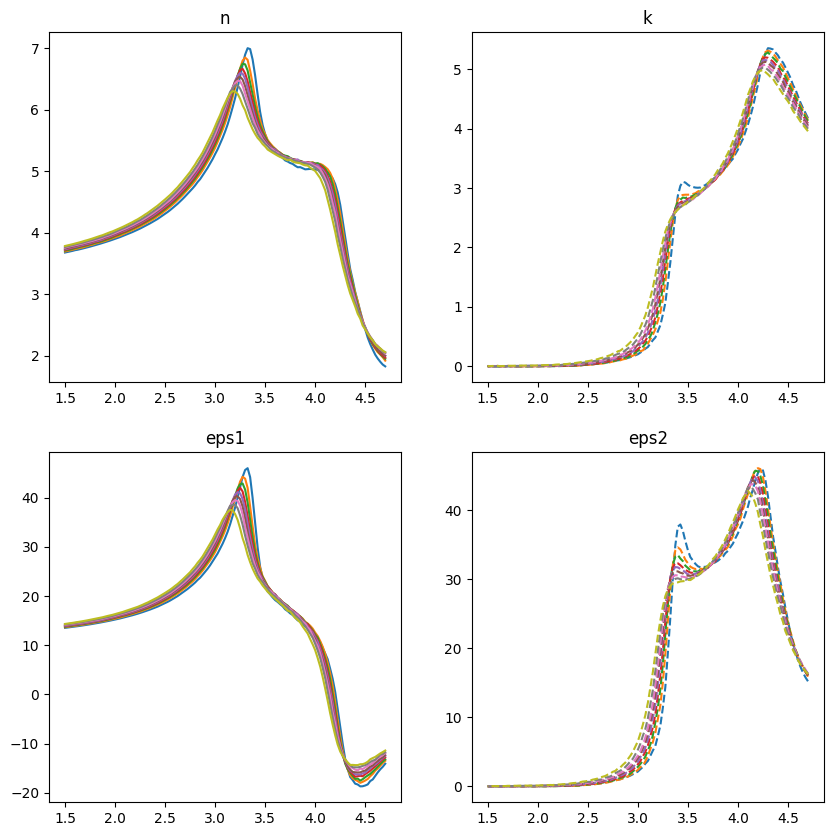

In [5]:
fig, ((ax1, ax4), (ax2, ax3)) = plt.subplots(2, 2, figsize=(10, 10))

for dataSet in dataSets:
    ax1.plot(dataSet.eV, dataSet.n, label=dataSet.temperature + "C")
    ax4.plot(dataSet.eV, dataSet.k, linestyle="--")
    
    eps1 = dataSet.n**2 - dataSet.k**2
    eps2 = 2*dataSet.n*dataSet.k
    
    ax2.plot(dataSet.eV, eps1, label=dataSet.temperature + "C")
    ax3.plot(dataSet.eV, eps2, linestyle="--")

ax1.set_title("n")
ax2.set_title("eps1")
ax3.set_title("eps2")
ax4.set_title("k")
# ax1.set_xlim(2.5, 3.5)

In [6]:
for i in range(len(dataSets)):
    for j in range(i + 1, len(dataSets)):
        obj1 = dataSets[i]
        obj2 = dataSets[j]
        
        # Perform the comparison
        if obj1.eV.all() != obj2.eV.all():
            print(f'Objects at temperatures {obj1.temperature} and {obj2.temperature} have different wavelengths')

In [7]:
tab10 = plt.get_cmap('tab10')
c1 = tab10(0)
nextColor = tab10(1)

def get_next_color(index):
    return tab10(index % 10)  # Ensure the index wraps around

7.80    8.68    6.47    5.84    5.36    k: 6.28
k: 10.14
k: 12.79
k: 17.57
5.16    k: 14.33
17.47    k: 14.08
26.61    k: 8.48
17.16    20.48    19.38    19.34    15.86    13.36    15.93    12.49    11.06    8.37    10.97    11.45    10.57    9.33    7.62    6.96    7.91    5.89    k: 5.70
k: 9.80
k: 14.38
k: 15.00
k: 26.67
k: 29.16
24.89    k: 14.53
55.48    48.82    k: 14.94
22.16    k: 53.63
7.05    k: 68.21
23.04    k: 35.18
38.61    k: 19.64
34.38    23.06    15.77    9.81    9.58    7.34    k: 5.14


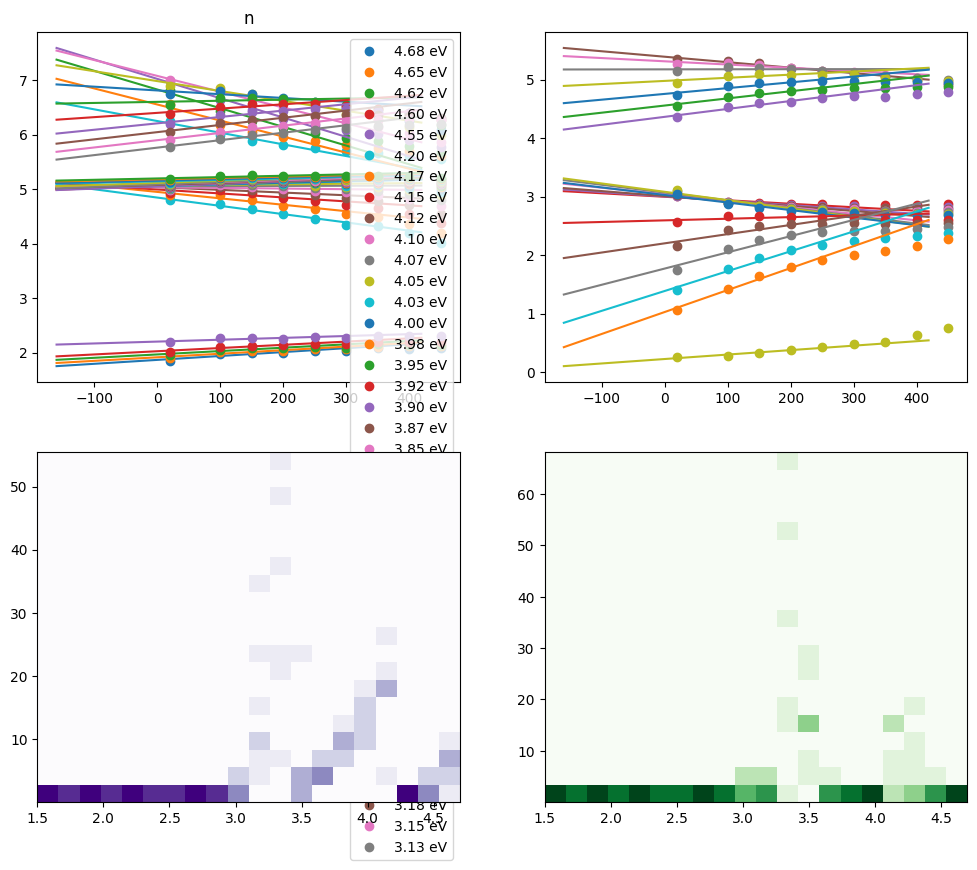

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax1, ax2, ax3, ax4 = axes.flatten()


firstPoly = 2
secondPoly = 2
cutTemp = 300
## save coefficients to ds object
# make new curve with coefficients extending to -120C
# profit

## simple 1d extrapolation
allTemps = np.array([int(dataSet.temperature) for dataSet in dataSets])
allWlens = dataSets[0].wl

dset0 = dataSets[0]
skip = 1
xg_eph = dset0.eV[::skip]

wlenDataSets = []

# wavelength loop
for i, eph in enumerate(xg_eph):
    
    yn_vs_temp = np.array([ds.n[i] for ds in dataSets])
    yk_vs_temp = np.array([ds.k[i] for ds in dataSets])
    
    tempOneD_data = TempData(temperature=allTemps, n=yn_vs_temp, k=yk_vs_temp, wl=hc/eph)
    wlenDataSets.append(tempOneD_data)

# linear fit to yn(x)
def linear(x, m, b):
    return m*x + b

# Define the polynomial model of degree N
def polynomial(x, *coeffs):
    return sum(c * x**i for i, c in enumerate(coeffs))

def doLinearFit(x, y, yerr, mguess = 0.2/400):
    ls = LeastSquares(x, y, yerr, linear)
    m = Minuit(ls, m = mguess, b = y[0])
    result = m.migrad()
    chi2red = m.fval / (len(x) - len(m.values))
    return m.values['m'], m.values['b'], chi2red

def doPolyFit(x, y, yerr, N):
    ls = LeastSquares(x, y, yerr, polynomial)
    m = Minuit(ls, *(0.1 for _ in range(N)))
    
    result = m.migrad()
    chi2red = m.fval / (len(x) - len(m.values))
    # print(m.values)
    # return 1, 1
    return [m.values[f'x{i}'] for i in range(N)], chi2red

chiSq_n = []
chiSq_k = []
colIndex = 0

for ds in wlenDataSets:
    mask = ds.temperature < cutTemp
    x = ds.temperature[mask]
    xTended = np.arange(-160, 420, 1)
    yn = ds.n[mask]
    yk = ds.k[mask]
    
    coeffs, chi2_red = doPolyFit(x, yn, 0.01 * np.ones_like(x), firstPoly)
    # ax1.plot(x, linear(x, mf, bf), color=col)
    
    # fit the n data
    if chi2_red > 5:
        col = get_next_color(colIndex); colIndex += 1
    
        ax1.plot(ds.temperature, ds.n, linestyle = "None", marker = "o", label=f'{ds.eV:.2f} eV', color=col)      
        
        coeffs, chi2_red = doPolyFit(x, yn, 0.01 * np.ones_like(x), secondPoly)
        # print(coeffs)
        ax1.plot(xTended, polynomial(xTended, *coeffs), color=col)        
        print(f"{chi2_red:0.2f}", end="    ")
    chiSq_n.append([ds.eV, chi2_red])
    
    # storing coeffs
    ds.nCoeffs = coeffs

    ## fit k data
    coeffs, chi2_red = doPolyFit(x, yk, 0.01 * np.ones_like(x), firstPoly)
    # ax2.plot(x, linear(x, mf, bf), color=col)
    
    if chi2_red > 5:
        col = get_next_color(colIndex); colIndex += 1
        
        ax2.plot(ds.temperature, ds.k, linestyle='None', marker='o', color=col)
        
        coeffs, chi2_red = doPolyFit(x, yk, 0.01 * np.ones_like(x), secondPoly)
        ax2.plot(xTended, polynomial(xTended, *coeffs), color=col)
        print(f"k: {chi2_red:0.2f}")
        
    chiSq_k.append([ds.eV, chi2_red])
    ds.kCoeffs = coeffs
    
    
ax1.set_title("n")
ax1.legend()

ax3.hist2d([c[0] for c in chiSq_n], [c[1] for c in chiSq_n], bins=20, cmap='Purples', label='n')
ax4.hist2d([c[0] for c in chiSq_k], [c[1] for c in chiSq_k], bins=20, cmap='Greens', label='k')

# ax3.set_xlim(0, 30)
    # print(f'Fit result for n at {ds.wl:.2f} nm: {result.values}')
# ax4.set_ylim(0, 5)
plt.show()

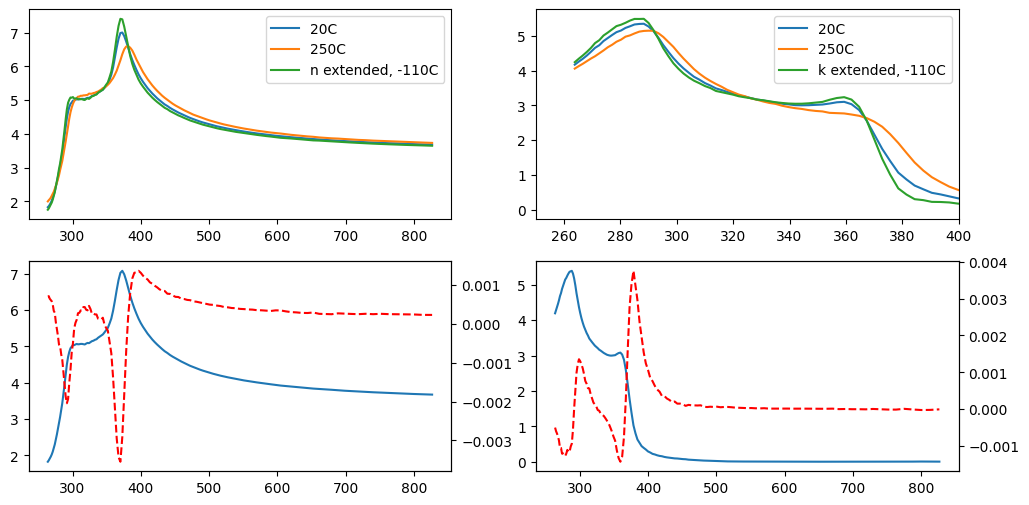

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
(ax1, ax2, ax3, ax4) = axes.flatten()

## extrapolating
tExt = -110
wlenOrder = hc/np.array([ds.eV for ds in wlenDataSets])
nTended = np.array([polynomial(tExt, *ds.nCoeffs) for ds in wlenDataSets])
kTended = np.array([polynomial(tExt, *ds.kCoeffs) for ds in wlenDataSets])

dsFixed = dataSets[0]
ax1.plot(hc/dsFixed.eV, dsFixed.n, label=dsFixed.temperature + "C")
ax2.plot(hc/dsFixed.eV, dsFixed.k, label=dsFixed.temperature + "C")

dsHot = dataSets[4]
ax1.plot(hc/dsHot.eV, dsHot.n, label=dsHot.temperature + "C")
ax2.plot(hc/dsHot.eV, dsHot.k, label=dsHot.temperature + "C")

ax1.plot(wlenOrder, nTended, label = 'n extended, -110C')
ax2.plot(wlenOrder, kTended, label='k extended, -110C')

## coefficients
cn1 = np.array([ds.nCoeffs[0] for ds in wlenDataSets])
cn2 = np.array([ds.nCoeffs[1] for ds in wlenDataSets])
# cn3 = np.array([ds.nCoeffs[2] for ds in wlenDataSets])

ax3.plot(wlenOrder, cn1, label='n1')
ax3.twinx().plot(wlenOrder, cn2, linestyle='--', label='n2', color='red')
# ax3.twinx().plot(wlenOrder, cn3, linestyle='-.', label='n2', color='green')

ck1 = np.array([ds.kCoeffs[0] for ds in wlenDataSets])
ck2 = np.array([ds.kCoeffs[1] for ds in wlenDataSets])
# ck3 = np.array([ds.kCoeffs[2] for ds in wlenDataSets])

ax4.plot(wlenOrder, ck1, label='k1')
ax4.twinx().plot(wlenOrder, ck2, linestyle='--', label='k2', color='red')
# ax4.twinx().plot(wlenOrder, ck3, linestyle='-.', label='k3', color='green')

# ax3.plot(wlenOrder, cn2, linestyle = "--", label='n2')

np.savetxt("vuye_silicon_extended160K_1dinterp.txt", np.array([wlenOrder, nTended, kTended]).T, delimiter=",", header="wl,n1,k", comments="", fmt="%.4f")

ax2.set_xlim(250, 400)
ax2.legend()
ax1.legend()

---
## Trying A 

[ 20 100 150 200 250 300 350 400 450]
[20.0, 100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0]
Explained variance: [0.93748627 0.05782998]
(9, 2)
(1, 129)


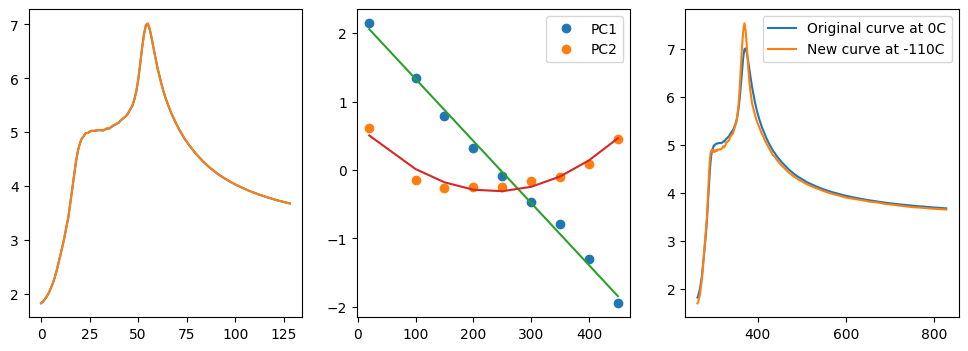

In [10]:
from sklearn.decomposition import PCA
import numpy as np
print(allTemps)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

# skip first data point because Z difference is 80C and not 50C
# Example data: each row is an x(y) curve for different Z
zTemps = [float(ds.temperature) for ds in dataSets]
print(zTemps)
Y = np.array([ds.n for ds in dataSets[:]])

# plot first row of data
# pca = PCA(n_components=3)  # Choose the number of components
# principal_components = pca.fit_transform(Y)

# # Use the principal components to reconstruct or extrapolate curves
# reconstructed_data = pca.inverse_transform(principal_components)


# center the data along each column
colMeans = np.mean(Y, axis=0)
# colMeans *= 0
Ycentered = Y - colMeans
# print(Y.shape)
# print(np.mean(Y[:, 0]))

# Apply PCA
Ncomp = 2
pca = PCA(n_components=Ncomp)  # Specify the number of principal components to keep
Y_pca = pca.fit_transform(Ycentered)  # Transformed data (principal components)

def doReconstruction(Y_pca, centeredData, colMeans):
    Y_reconstructed = pca.inverse_transform(Y_pca)  # Reconstructed data
    Y_reconstructed_full = Y_reconstructed + colMeans
    return Y_reconstructed_full

Y_reconstructed = pca.inverse_transform(Y_pca)  # Reconstructed data
Y_reconstructed_full = Y_reconstructed + colMeans
ax1.plot(Y[0], label='Original, first row')
ax1.plot(Y_reconstructed_full[0], label='Reconstructed, first row')

# Explained variance
explained_variance = pca.explained_variance_ratio_
print("Explained variance:", explained_variance)

print(Y_pca.shape)
for i in range(Ncomp):
    ax2.plot(zTemps, Y_pca[:, i], linestyle = "None", marker = "o", label=f'PC{i+1}')
ax2.legend()

# fitting the polynomials
coeff1 = Y_pca[:, 0]
mc1, bc1, chi2r = doLinearFit(zTemps, coeff1, 0.01 * np.ones_like(allTemps), mguess=-4/430)
ax2.plot(zTemps, linear(allTemps, mc1, bc1), label='Linear fit')
coeff1_newZ = linear(-110, mc1, bc1)

coeff2 = Y_pca[:, 1]
cfit2, chi2r = doPolyFit(zTemps, coeff2, 0.01 * np.ones_like(allTemps), 3)
ax2.plot(zTemps, polynomial(allTemps, *cfit2), label='Poly fit')

## new coefficients
columCoeffs = Y_pca[0, :]
columCoeffs[0] = coeff1_newZ
columCoeffs[1] = polynomial(-110, *cfit2)

newYcurve = pca.inverse_transform(columCoeffs.reshape(1, -1)) + colMeans
print(newYcurve.shape)

ax3.plot(allWlens, Y[0], label='Original curve at 0C')
ax3.plot(allWlens, newYcurve[0], label='New curve at -110C')
ax3.legend()

Explained variance: [0.9495872  0.04625055 0.00243311]
(9, 3)
(1, 129)


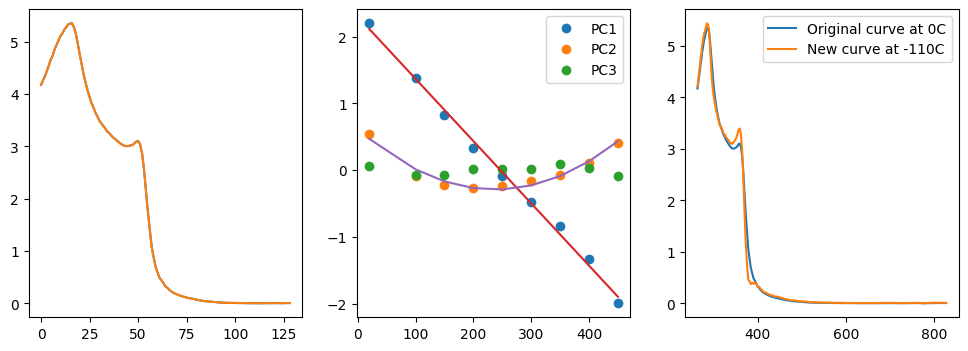

In [11]:
## repeat for k
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4))

zTemps = [float(ds.temperature) for ds in dataSets]
Y = np.array([ds.k for ds in dataSets[:]])

# center the data along each column
colMeans = np.mean(Y, axis=0)
# colMeans *= 0
Ycentered = Y - colMeans

# Apply PCA
Ncomp = 3
pca = PCA(n_components=Ncomp)  # Specify the number of principal components to keep
Y_pca = pca.fit_transform(Ycentered)  # Transformed data (principal components)

Y_reconstructed = pca.inverse_transform(Y_pca)  # Reconstructed data
Y_reconstructed_full = Y_reconstructed + colMeans
ax1.plot(Y[0], label='Original, first row')
ax1.plot(Y_reconstructed_full[0], label='Reconstructed, first row')

# Explained variance
explained_variance = pca.explained_variance_ratio_
print("Explained variance:", explained_variance)

print(Y_pca.shape)
for i in range(Ncomp):
    ax2.plot(zTemps, Y_pca[:, i], linestyle = "None", marker = "o", label=f'PC{i+1}')
ax2.legend()

# fitting the polynomials
coeff1 = Y_pca[:, 0]
mc1, bc1, chi2r = doLinearFit(zTemps, coeff1, 0.01 * np.ones_like(allTemps), mguess=-4/430)
ax2.plot(zTemps, linear(allTemps, mc1, bc1), label='Linear fit')
coeff1_newZ = linear(-110, mc1, bc1)

coeff2 = Y_pca[:, 1]
cfit2, chi2r = doPolyFit(zTemps, coeff2, 0.01 * np.ones_like(allTemps), 3)
ax2.plot(zTemps, polynomial(allTemps, *cfit2), label='Poly fit')

## new coefficients
columCoeffs = Y_pca[0, :]
columCoeffs[0] = coeff1_newZ
columCoeffs[1] = polynomial(-110, *cfit2)

newYcurve_k = pca.inverse_transform(columCoeffs.reshape(1, -1)) + colMeans
print(newYcurve_k.shape)

ax3.plot(allWlens, Y[0], label='Original curve at 0C')
ax3.plot(allWlens, newYcurve_k[0], label='New curve at -110C')
ax3.legend()

np.savetxt("vuye_n_160k_PCA.txt", np.array([allWlens, newYcurve_k[0]]).T, delimiter=",", header="wl,n", comments="", fmt="%.4f")